### Part A: Conceptual Understanding (Theory)
- **Logistic Regression**: A statistical algorithm used for binary classification that predicts the probability of an outcome by fitting data to a logit function. It is highly interpretable and efficient for linear classification problems.
- **Classification Metrics**: Accuracy can be misleading in imbalanced datasets because a model predicting only the majority class will still score highly. Metrics like Precision, Recall, and F1-score evaluate how well the model handles the minority (risk) class.
- **Type-I vs. Type-II Error**: Type-I Error (False Positive) is classifying a low-risk customer as high-risk. Type-II Error (False Negative) is missing a high-risk customer, which is more dangerous for a bank as it leads to actual financial loss.
- **Precision, Recall, F1, TPR, FPR**:
  - *Precision*: Out of all predicted high-risk customers, how many were actually high-risk?
  - *Recall (TPR)*: Out of all actual high-risk customers, how many did we identify?
  - *F1-Score*: Harmonic mean of precision and recall.
  - *FPR*: False Positive Rate; proportion of safe customers flagged as risky.
- **AUC-ROC**: The Area Under the Receiver Operating Characteristic Curve plots TPR vs FPR at different thresholds. It measures the model's ability to distinguish between classes (1.0 is perfect, 0.5 is random guessing).
- **Imbalanced Data**: Models trained on imbalanced data become biased towards the majority class, resulting in terrible recall for the minority class (high-risk customers).

#  Part B: Dataset Understanding & Preparation

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
    classification_report, make_scorer)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

In [2]:
DF = pd.read_csv("Risk_Alert_Classifier_Dataset_4600.csv")
DF

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,504596,40.0,Male,North,NaN,39337.0,645.0,0.101,0,8.8,49,12591.0,0,0,0,23,2025-09-14,28947,0
4596,504597,35.0,Female,Central,Unemployed,34465.0,622.0,0.325,0,7.3,45,20146.0,3,0,4,18,2025-11-25,32475,0
4597,504598,31.0,Female,East,Self-Employed,NaN,693.0,0.583,1,7.1,36,16338.0,1,1,1,89,2025-09-16,52776,0
4598,504599,43.0,Male,East,Salaried,15000.0,540.0,0.915,4,16.0,60,13870.0,1,1,3,19,2025-09-07,20615,1


In [3]:
DF.head()

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [4]:
DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

In [5]:
DF.isnull().sum()

customer_id                    0
age                          140
gender                         0
region                       102
employment_type              144
annual_income_inr            166
credit_score                 216
credit_utilization_ratio     147
missed_payments_12m            0
avg_late_payment_days          0
monthly_transaction_count      0
monthly_spend_inr            129
cash_advance_count_6m          0
complaints_last_6m             0
failed_login_attempts_3m       0
account_tenure_months          0
last_transaction_date          0
debt_balance_inr               0
risk_status                    0
dtype: int64

In [6]:
DF = DF.drop(columns=['customer_id', 'last_transaction_date'], errors='ignore')

In [7]:
DF.head()

,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,debt_balance_inr,risk_status
0,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,87273,0
1,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,20600,0
2,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,47565,0
3,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,43803,1
4,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,12008,0


In [8]:
X = DF.drop(columns=['risk_status'])
y = DF['risk_status']

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

num_transformer = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('imputer', KNNImputer(n_neighbors=5))
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

In [11]:
results = []
fitted_models = {}
def evaluate_model(name, model, X_eval=X_test, y_eval=y_test, add_result=True):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba") else None
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall (High Risk)": recall_score(y_eval, pred, zero_division=0),
        "F1 (High Risk)": f1_score(y_eval, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_eval, proba) if proba is not None else np.nan
    }
    if add_result:
        results.append(row)
    print(pd.Series(row).to_string())
    print("\\nClassification report:\\n", classification_report(y_eval, pred, zero_division=0))
    cm = confusion_matrix(y_eval, pred, labels=[0,1])
    ConfusionMatrixDisplay(cm, display_labels=["Low Risk (0)", "High Risk (1)"]).plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print(f"Type-I error (FP): {fp}; Type-II error (FN): {fn}")
    return row

## Part C:Baseline Logistic Regression

Model                 Logistic Regression (baseline)
Accuracy                                         1.0
Precision                                        1.0
Recall (High Risk)                               1.0
F1 (High Risk)                                   1.0
AUC-ROC                                          1.0
\nClassification report:\n               precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



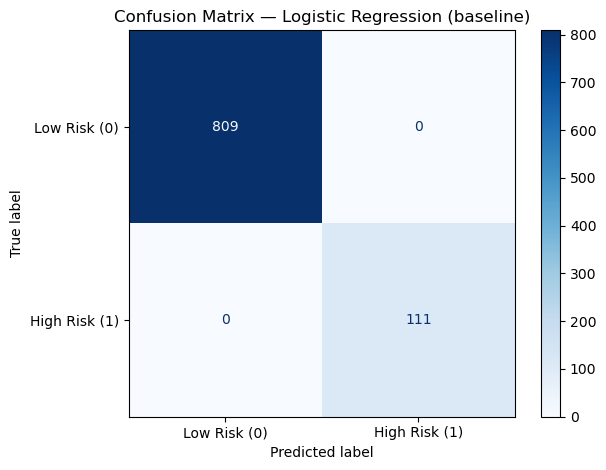

TN=809, FP=0, FN=0, TP=111
Type-I error (FP): 0; Type-II error (FN): 0


In [12]:
baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, class_weight=None, random_state=42))
])
baseline.fit(X_train, y_train)
fitted_models["Logistic Regression (baseline)"] = baseline
baseline_row = evaluate_model("Logistic Regression (baseline)", baseline)

## Part D:Imbalance handling

Model                 Under-sampling + Logistic Regression
Accuracy                                          0.996739
Precision                                         0.973684
Recall (High Risk)                                     1.0
F1 (High Risk)                                    0.986667
AUC-ROC                                                1.0
\nClassification report:\n               precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.97      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



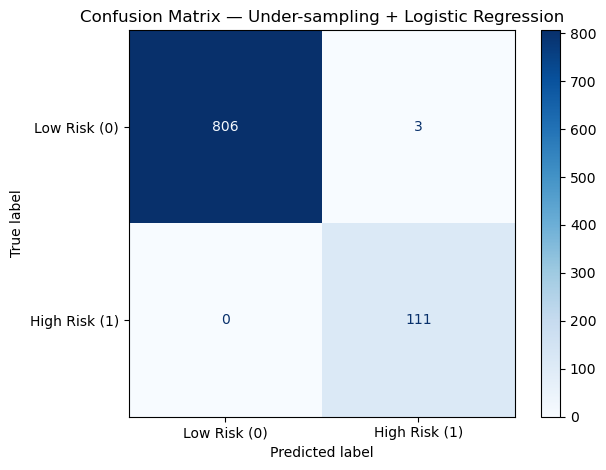

TN=806, FP=3, FN=0, TP=111
Type-I error (FP): 3; Type-II error (FN): 0
Model                 Over-sampling + Logistic Regression
Accuracy                                         0.997826
Precision                                        0.982301
Recall (High Risk)                                    1.0
F1 (High Risk)                                   0.991071
AUC-ROC                                               1.0
\nClassification report:\n               precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.98      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



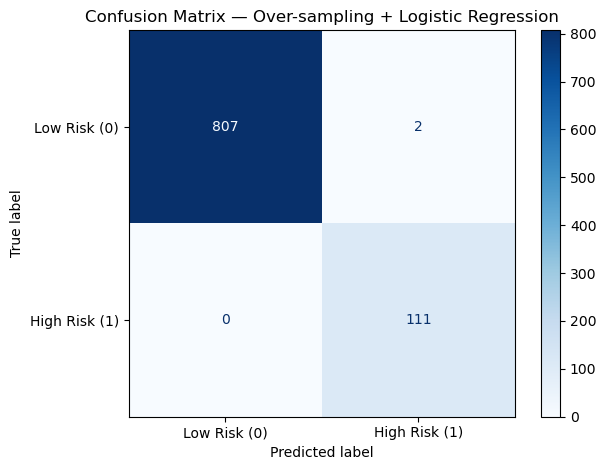

TN=807, FP=2, FN=0, TP=111
Type-I error (FP): 2; Type-II error (FN): 0


  File "d:\Users\mantr\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\Users\mantr\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Users\mantr\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Users\mantr\anaconda3\Lib\subprocess.

Model                 SMOTE + Logistic Regression
Accuracy                                 0.997826
Precision                                0.982301
Recall (High Risk)                            1.0
F1 (High Risk)                           0.991071
AUC-ROC                                       1.0
\nClassification report:\n               precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.98      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



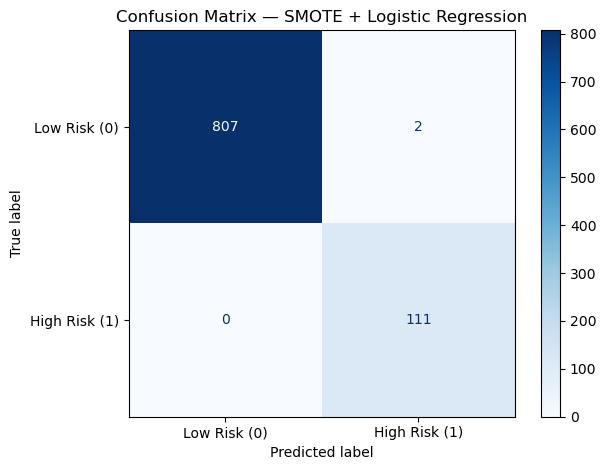

TN=807, FP=2, FN=0, TP=111
Type-I error (FP): 2; Type-II error (FN): 0
Model                 ADASYN + Logistic Regression
Accuracy                                  0.996739
Precision                                 0.973684
Recall (High Risk)                             1.0
F1 (High Risk)                            0.986667
AUC-ROC                                        1.0
\nClassification report:\n               precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.97      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



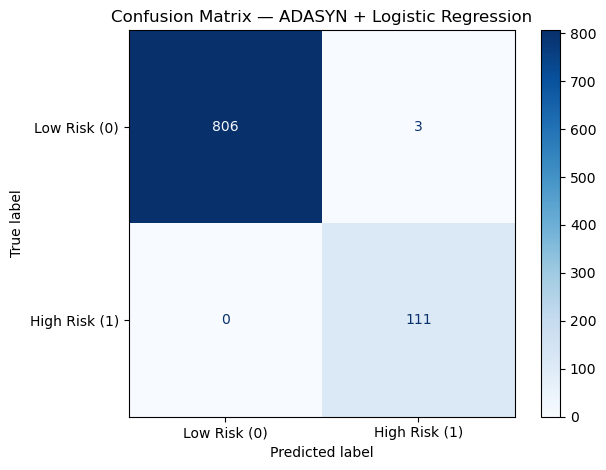

TN=806, FP=3, FN=0, TP=111
Type-I error (FP): 3; Type-II error (FN): 0


In [13]:
samplers = {
    "Under-sampling + Logistic Regression": RandomUnderSampler(random_state=42),
    "Over-sampling + Logistic Regression": RandomOverSampler(random_state=42),
    "SMOTE + Logistic Regression": SMOTE(random_state=42, k_neighbors=5),
    "ADASYN + Logistic Regression": ADASYN(random_state=42, n_neighbors=5)
}
for name, sampler in samplers.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("sampler", sampler),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ])
    try:
        pipe.fit(X_train, y_train)
        fitted_models[name] = pipe
        evaluate_model(name, pipe)
    except Exception as e:
        print(f"{name} skipped because the sampler could not run: {e}")

## Part E : Tree-based classifiers and overfitting

\nDecision Tree: train accuracy=1.000, test accuracy=0.974, train recall=1.000, test recall=0.901
Model                 Decision Tree
Accuracy                   0.973913
Precision                  0.884956
Recall (High Risk)         0.900901
F1 (High Risk)             0.892857
AUC-ROC                    0.942416
\nClassification report:\n               precision    recall  f1-score   support

           0       0.99      0.98      0.99       809
           1       0.88      0.90      0.89       111

    accuracy                           0.97       920
   macro avg       0.94      0.94      0.94       920
weighted avg       0.97      0.97      0.97       920



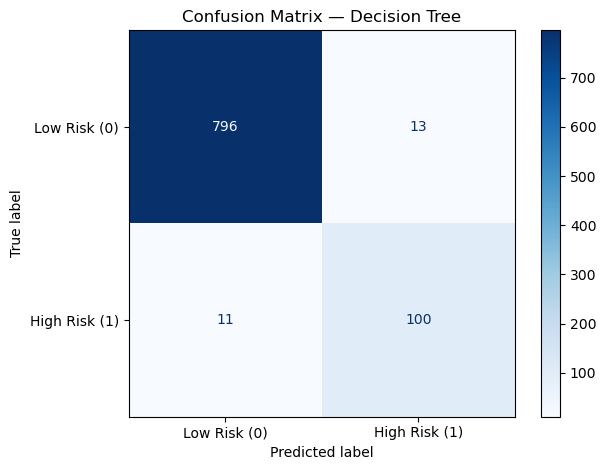

TN=796, FP=13, FN=11, TP=100
Type-I error (FP): 13; Type-II error (FN): 11
\nRandom Forest: train accuracy=1.000, test accuracy=0.995, train recall=1.000, test recall=0.955
Model                 Random Forest
Accuracy                   0.994565
Precision                       1.0
Recall (High Risk)         0.954955
F1 (High Risk)             0.976959
AUC-ROC                    0.999978
\nClassification report:\n               precision    recall  f1-score   support

           0       0.99      1.00      1.00       809
           1       1.00      0.95      0.98       111

    accuracy                           0.99       920
   macro avg       1.00      0.98      0.99       920
weighted avg       0.99      0.99      0.99       920



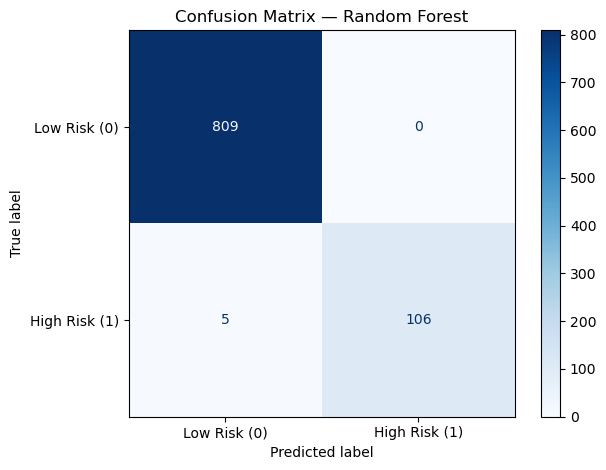

TN=809, FP=0, FN=5, TP=106
Type-I error (FP): 0; Type-II error (FN): 5


In [14]:
tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced"))
])
forest = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=180, random_state=42,
                                     class_weight="balanced_subsample", n_jobs=-1))
])
for name, model in [("Decision Tree", tree), ("Random Forest", forest)]:
    model.fit(X_train, y_train)
    fitted_models[name] = model
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    print(f"\\n{name}: train accuracy={accuracy_score(y_train, train_pred):.3f}, test accuracy={accuracy_score(y_test, test_pred):.3f}, "
          f"train recall={recall_score(y_train, train_pred):.3f}, test recall={recall_score(y_test, test_pred):.3f}")
    evaluate_model(name, model)

## Part F : Hyperparameter tuning

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Decision Tree best CV recall: 0.9395519680754579 \nParams: {'model__min_samples_split': 2, 'model__min_samples_leaf': 5, 'model__max_depth': 5, 'model__criterion': 'gini'}
Random Forest best CV recall: 0.9551968075458008 \nParams: {'model__n_estimators': 180, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 5}
Model                 Tuned Decision Tree (RandomizedSearchCV)
Accuracy                                              0.967391
Precision                                             0.804511
Recall (High Risk)                                    0.963964
F1 (High Risk)                                        0.877049
AUC-ROC                                               0.959866
\nClassification report:\n               precision    recall  f1-score   support

           0       0.99      0.97      0.98 

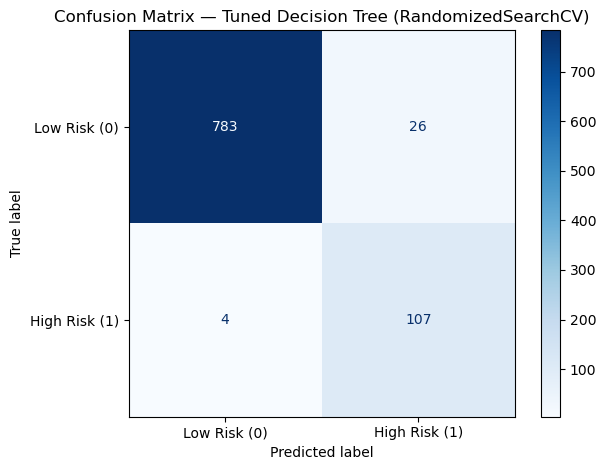

TN=783, FP=26, FN=4, TP=107
Type-I error (FP): 26; Type-II error (FN): 4
Model                 Tuned Random Forest (RandomizedSearchCV)
Accuracy                                              0.993478
Precision                                             0.948718
Recall (High Risk)                                         1.0
F1 (High Risk)                                        0.973684
AUC-ROC                                               0.999699
\nClassification report:\n               precision    recall  f1-score   support

           0       1.00      0.99      1.00       809
           1       0.95      1.00      0.97       111

    accuracy                           0.99       920
   macro avg       0.97      1.00      0.98       920
weighted avg       0.99      0.99      0.99       920



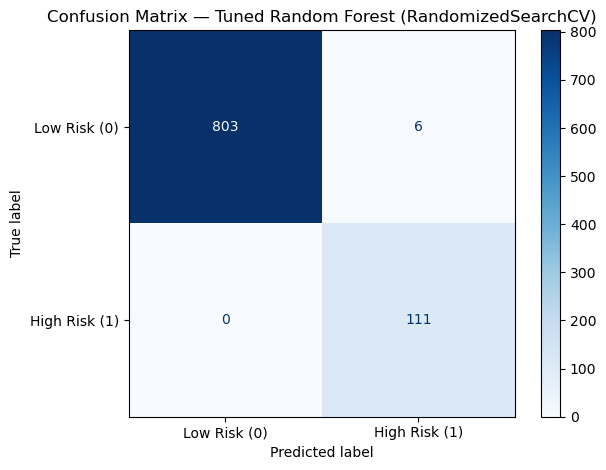

TN=803, FP=6, FN=0, TP=111
Type-I error (FP): 6; Type-II error (FN): 0


In [15]:
recall_scorer = make_scorer(recall_score, pos_label=1, zero_division=0)
dt_pipe = Pipeline(steps=[("preprocessor", preprocessor),
                          ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced"))])
rf_pipe = Pipeline(steps=[("preprocessor", preprocessor),
                          ("model", RandomForestClassifier(random_state=42, n_jobs=-1,
                                                           class_weight="balanced_subsample"))])
dt_params = {
    "model__max_depth": [3, 5, 8, 12, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__criterion": ["gini", "entropy", "log_loss"]
}
rf_params = {
    "model__n_estimators": [120, 180, 250, 350],
    "model__max_depth": [5, 8, 12, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7],
}
dt_search = RandomizedSearchCV(dt_pipe, dt_params, n_iter=8, scoring=recall_scorer,
                               cv=3, random_state=42, n_jobs=-1, verbose=1)
rf_search = RandomizedSearchCV(rf_pipe, rf_params, n_iter=8, scoring=recall_scorer,
                               cv=3, random_state=42, n_jobs=-1, verbose=1)
dt_search.fit(X_train, y_train)
rf_search.fit(X_train, y_train)
print("Decision Tree best CV recall:", dt_search.best_score_, "\\nParams:", dt_search.best_params_)
print("Random Forest best CV recall:", rf_search.best_score_, "\\nParams:", rf_search.best_params_)
tuned_candidates = {"Tuned Decision Tree (RandomizedSearchCV)": dt_search.best_estimator_,
                    "Tuned Random Forest (RandomizedSearchCV)": rf_search.best_estimator_}
for name, model in tuned_candidates.items():
    fitted_models[name] = model
    evaluate_model(name, model)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Grid-search model family: Random Forest
Best GridSearchCV recall: 0.9551968075458008
Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__n_estimators': 180}
Model                 Final GridSearchCV Model
Accuracy                              0.994565
Precision                             0.956897
Recall (High Risk)                         1.0
F1 (High Risk)                        0.977974
AUC-ROC                               0.999766
\nClassification report:\n               precision    recall  f1-score   support

           0       1.00      0.99      1.00       809
           1       0.96      1.00      0.98       111

    accuracy                           0.99       920
   macro avg       0.98      1.00      0.99       920
weighted avg       0.99      0.99      0.99       920



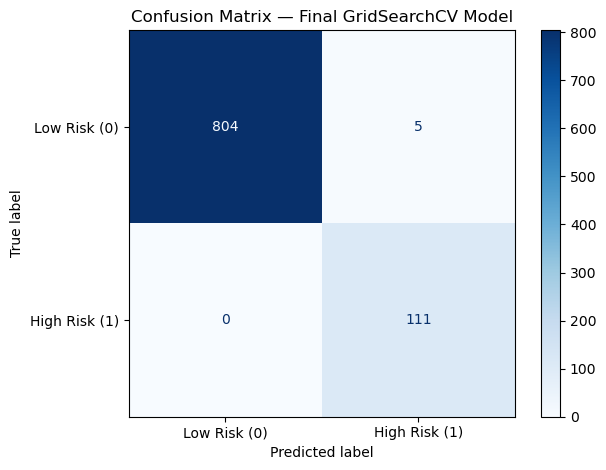

TN=804, FP=5, FN=0, TP=111
Type-I error (FP): 5; Type-II error (FN): 0


In [16]:
if dt_search.best_score_ >= rf_search.best_score_:
    chosen_search = dt_search
    chosen_name = "Decision Tree"
    best_params = dt_search.best_params_
    model_key = "model__"
else:
    chosen_search = rf_search
    chosen_name = "Random Forest"
    best_params = rf_search.best_params_
    model_key = "model__"

if chosen_name == "Decision Tree":
    grid = {
        "model__max_depth": list(dict.fromkeys([best_params["model__max_depth"], 5, 8, 12])),
        "model__min_samples_split": list(dict.fromkeys([best_params["model__min_samples_split"], 2, 5, 10])),
        "model__min_samples_leaf": list(dict.fromkeys([best_params["model__min_samples_leaf"], 1, 2, 5]))
    }
    base_pipe = dt_pipe
else:
    grid = {
        "model__n_estimators": list(dict.fromkeys([best_params["model__n_estimators"], 180, 250])),
        "model__max_depth": list(dict.fromkeys([best_params["model__max_depth"], 8, 12])),
        "model__min_samples_leaf": list(dict.fromkeys([best_params["model__min_samples_leaf"], 1, 2]))
    }
    base_pipe = rf_pipe

grid_search = GridSearchCV(base_pipe, grid, scoring=recall_scorer, cv=3, n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)
final_model = grid_search.best_estimator_
fitted_models["Final GridSearchCV Model"] = final_model
print("Grid-search model family:", chosen_name)
print("Best GridSearchCV recall:", grid_search.best_score_)
print("Best parameters:", grid_search.best_params_)
final_row = evaluate_model("Final GridSearchCV Model", final_model)

## Part G : ROC curves and AUC comparison

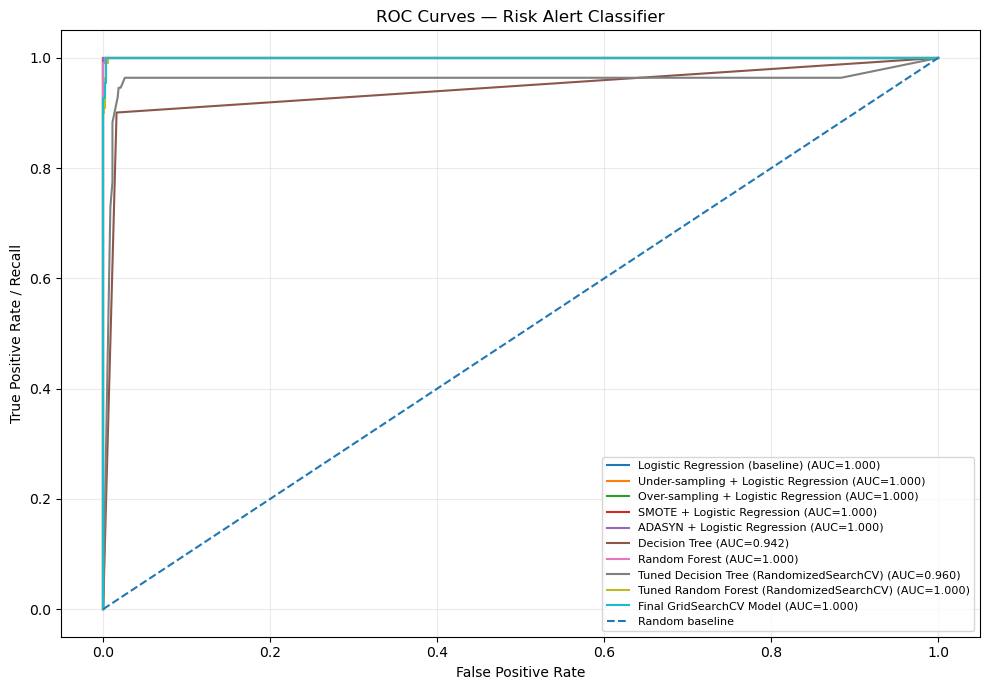

In [17]:
plt.figure(figsize=(10, 7))
roc_rows = []
for name, model in fitted_models.items():
    try:
        probs = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, probs)
        auc_value = roc_auc_score(y_test, probs)
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
        roc_rows.append({"Model": name, "AUC-ROC": auc_value})
    except Exception as e:
        print("ROC skipped for", name, e)
plt.plot([0,1], [0,1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC Curves — Risk Alert Classifier")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## Part H — Final analysis, business interpretation and artifact export

- **False negative (FN):** a high-risk customer predicted low-risk. This is the most important error to minimize for early warning because the bank may miss an opportunity to investigate or intervene.
- **False positive (FP):** a low-risk customer predicted high-risk. This can create unnecessary reviews, friction, and operational cost.
- Select the final model using high-risk recall first, then F1 and AUC as supporting evidence. Review the comparison table generated above rather than assuming a model is best before results are measured.
- The model is a decision-support alert, not a definitive fraud/default finding. Monitor drift, calibrate thresholds using validation data, and review fairness/privacy before production use.

In [20]:
import pickle
import json
import joblib
from pathlib import Path

In [ ]:
# Streamlit app (app.py) loads this exact filename
joblib.dump(final_model, "risk_alert_model.joblib")
# Optional pickle copy of the same model
with open("Best_Model.pkl", "wb") as file:
    pickle.dump(final_model, file)
print("Saved risk_alert_model.joblib")

In [ ]:
metadata = {
    "input_columns": X.columns.tolist(),
    "threshold": 0.50,
    "positive_class": 1,
    "positive_class_label": "High Risk",
    "dataset_rows": int(len(DF)),
    "test_size": 0.20,
    "random_state": 42,
    "best_model_family": chosen_name,
    "grid_search_best_params": {k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in grid_search.best_params_.items()}
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)
print("Saved model_metadata.json")

In [ ]:
# Sanity check: reload the saved files exactly as app.py does
loaded_model = joblib.load("risk_alert_model.joblib")
with open("model_metadata.json") as f:
    loaded_meta = json.load(f)
sample = X_test.iloc[[0]][loaded_meta["input_columns"]]
print("Sample high-risk probability:", float(loaded_model.predict_proba(sample)[:, 1][0]))